# Paket C — Kenar ve şablon (6. adım), D4
Kenar haritası ve şablon skoru "bu bir yelek" sonucunu tek başına vermez. Şablon skoru başarı yüzdesi ya da olasılık değildir (H3, S3).

> Colab: defteri Drive'da açın (çift tık → *Birlikte aç → Google Colaboratory*). İlk hücre Drive'ı bağlar ve proje klasörünü kendisi bulur. Defterde yaptığınız değişiklik doğrudan Drive'daki dosyaya kaydedilir; *Drive'a kopya kaydet* **kullanmayın** (kopya "Colab Notebooks" klasörüne gider, grup göremez).

In [10]:
# --- Kurulum: Google Drive'ı bağlar ve proje klasörünü bulur (GitHub gerekmez) ---
PROJE = ''   # boş bırakın, otomatik bulunur; bulunamazsa Drive'daki yolu yazın: '/content/drive/MyDrive/.../yelek-tespiti'
import os, sys, glob, unicodedata
sys.dont_write_bytecode = True                      # Drive'daki src/ klasörüne __pycache__ yazılmasın

def _proje_mi(p):
    return os.path.isfile(os.path.join(p, 'src', 'common.py')) and os.path.isfile(os.path.join(p, 'config', 'params.json'))

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = PROJE.strip().rstrip('/')
    if PROJE and not _proje_mi(PROJE):               # Türkçe harf kodlaması farkı (ör. 'Ödevler')
        PROJE = next((unicodedata.normalize(f, PROJE) for f in ('NFC', 'NFD')
                      if _proje_mi(unicodedata.normalize(f, PROJE))), PROJE)
    if not PROJE:                                    # Drive'ım ve ortak drive'larda 4 klasör derinliğe kadar ara
        for d in range(5):
            bulunan = sorted({os.path.dirname(os.path.dirname(p))
                              for k in ('/content/drive/MyDrive', '/content/drive/Shareddrives')
                              for p in glob.glob(os.path.join(k, *['*'] * d, 'src', 'common.py'))})
            bulunan = [p for p in bulunan if _proje_mi(p)]
            if bulunan:
                PROJE = bulunan[0]
                if len(bulunan) > 1:
                    print('Birden fazla proje klasörü bulundu, ilki kullanılıyor:', *bulunan, sep='\n  ')
                break
    if not PROJE or not _proje_mi(PROJE):
        raise FileNotFoundError("Proje klasörü bulunamadı. Drive'da paylaşılan 'yelek-tespiti' klasörüne sağ tık -> "
                                "Düzenle -> Kısayol ekle -> Drive'ım; sonra bu hücreyi yeniden çalıştırın "
                                "(ya da yukarıda PROJE = '/content/drive/MyDrive/...' yazın).")
    os.chdir(PROJE)
elif os.path.basename(os.getcwd()) == 'notebooks':  # Colab dışında (Jupyter / VS Code)
    os.chdir('..')
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
try:                                                # Colab'ın Python 3.13 sürümünde autoreload bozuk; varsa açılır, yoksa geçilir
    get_ipython().run_line_magic('reload_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # defter boyutu küçük kalsın
from common import *
gt, P = load_gt(), load_params()
durum()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü : /content/drive/MyDrive/Yelek tespit deneme/yelek-tespiti-drive/yelek-tespiti
Görüntüler    : 20/20 hazır (data/images_1024)
gt.json       : 20 görüntü, 20 tanesinde kutu var
params dondu mu: True 2026-11-10T21:09:21
Kayıtlar      : 1 dosya kaydı, son: dondurma-2 (2026-11-10T21:09:21)


## 6a — Sobel ve Canny (geliştirme görüntüsünde göz atma)

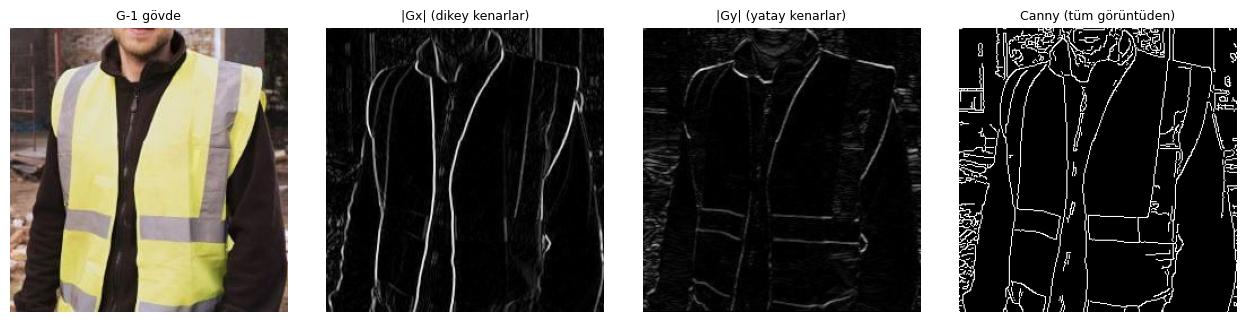

In [11]:
import edge
edge.show_sobel('G-1', gt, P, path=RES / 'fig' / 'sobel_G-1.png');

## 6b — Şablonun kesileceği yeri seç (yalnız geliştirme görüntüsü)
Kenar = yelek kutusunun kısa kenarının yarısı. Şerit içeren sol üst köşeyi `P['template']['cut_xy']`'e yazın ve B dondurmadan önce
params.json'a kaydedin (`save_params(P)`; B'ye haber verin — aynı anda iki kişi params.json'a yazmasın).

kare kenarı 99px, sol üst köşe [316, 191] (görüntü koordinatı); yelek kutusu [267, 123, 465, 358]


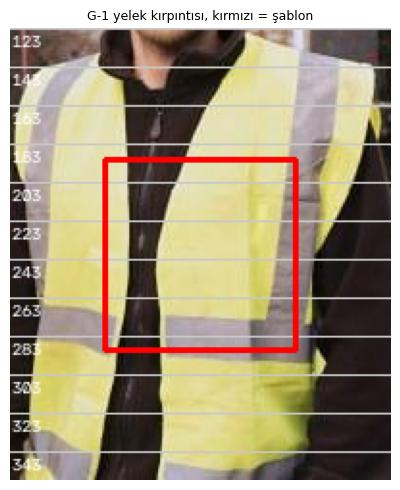

In [12]:
import template
P['template']['dev_id'] = 'G-1'
P['template']['cut_xy'] = None          # örn. [x, y]
template.preview_cut(P, gt, path=RES / 'fig' / 'template_cut.png');

,seri,deger,skor,uzaklik_px,dolgu_orani
0,referans,"0° / 1,0",1.000000,0.000000,0.000000
1,döndürme,10°,0.628590,4.123106,0.073462
2,döndürme,20°,0.641203,81.412530,0.123661
3,döndürme,30°,0.583389,83.862983,0.154678
4,ölçek,0.9,0.939766,3.162278,0.000000
5,ölçek,0.8,0.879747,8.602325,0.000000
6,ölçek,0.7,0.810751,14.212670,0.000000


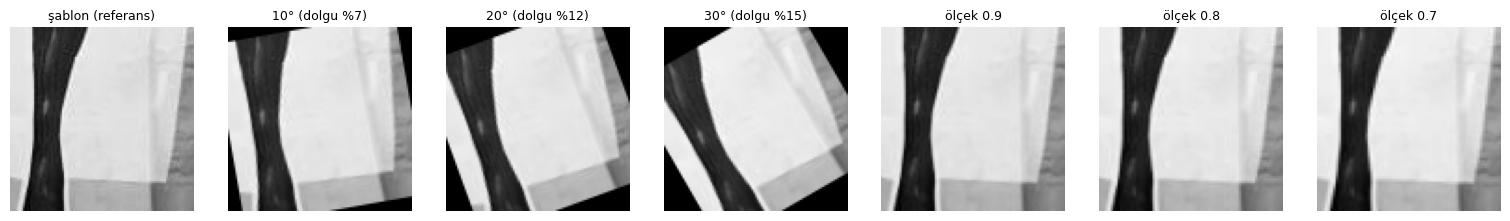

In [13]:
ser = template.series(P, gt)      # aynı görüntüde: yalnız döndürme, yalnız ölçekleme
ser

## Dondurmadan sonra: bütün görüntülerde kenar oranları ve kontrol araması

In [14]:
P = load_params()
ed = edge.run(DEV_IDS + CTRL_IDS, gt, P)
edge.side_by_side(ed[ed.ayirim == 'kontrol'])

canny_orani               gy_gx              
            count   mean median count   mean median
yelek                                              
False           6  0.127  0.141     6  0.942  0.842
True            6  0.103  0.075     6  0.797  0.750

In [15]:
ed[ed.ayirim == 'kontrol'].sort_values(['yelek', 'id'])

,id,ayirim,kisi,secilen,yelek,canny_orani,gy_gx,canny
17,K-10,kontrol,0,True,False,0.106774,0.659982,50/150
18,K-11,kontrol,0,True,False,0.144758,0.806868,50/150
12,K-5,kontrol,0,True,False,0.146153,0.703522,50/150
14,K-7,kontrol,0,True,False,0.033512,0.956030,50/150
15,K-8,kontrol,0,True,False,0.136458,1.648252,50/150
16,K-9,kontrol,0,True,False,0.195029,0.876644,50/150
8,K-1,kontrol,0,True,True,0.114854,0.741047,50/150
19,K-12,kontrol,0,True,True,0.020427,1.193655,50/150
9,K-2,kontrol,0,True,True,0.042011,0.567240,50/150
10,K-3,kontrol,0,True,True,0.037800,0.738316,50/150


In [16]:
tc = template.control_scores(CTRL_IDS, gt, P)
display(tc)
template.side_by_side(tc)

,id,kisi,secilen,yelek,olcek,skor,neden
0,K-1,0,True,True,0.591270,0.566143,
1,K-2,0,True,True,2.261905,0.532228,
2,K-3,0,True,True,1.706349,0.486768,
3,K-4,0,True,True,0.166667,0.612197,
4,K-5,0,True,False,0.908730,0.468882,
5,K-6,0,True,True,0.623016,0.617481,
6,K-7,0,True,False,1.936508,0.413843,
7,K-8,0,True,False,0.722222,0.363584,
8,K-9,0,True,False,1.027778,0.237955,
9,K-10,0,True,False,0.896825,0.219335,


,count,mean,median,max
yelek,,,,
False,6,0.357,0.389,0.469
True,6,0.531,0.549,0.617


## 6c — Kanıtın değeri (ölçüme dayalı tek cümle)
`color.csv` ile yan yana koyun: renk kuralının yanlış verdiği görüntülerde kenar/şablon farklı bir şey söylüyor mu?

In [17]:
import pandas as pd
col = pd.read_csv(RES / 'color.csv')
sel = ed[(ed.secilen) & (ed.ayirim == 'kontrol')][['id', 'yelek', 'canny_orani', 'gy_gx']]
tsel = tc[tc.secilen][['id', 'skor']]
col[['id', 'dogru_sinif', 'kural_sinifi', 'govde_maske_orani']].merge(sel, on='id').merge(tsel, on='id')

,id,dogru_sinif,kural_sinifi,govde_maske_orani,yelek,canny_orani,gy_gx,skor
0,K-1,Yelek giyili,Yelek giyili,0.366975,True,0.114854,0.741047,0.566143
1,K-2,Yelek giyili,Yelek giyili,0.508691,True,0.042011,0.567240,0.532228
2,K-3,Yelek giyili,Yelek yok,0.067609,True,0.037800,0.738316,0.486768
3,K-4,Yelek giyili,Yelek giyili,0.356499,True,0.295367,0.783200,0.612197
4,K-5,Yelek yok,Yelek yok,0.085935,False,0.146153,0.703522,0.468882
5,K-6,Yelek giyili,Yelek giyili,0.196151,True,0.107854,0.759094,0.617481
6,K-7,Yelek yok,Yelek giyili,0.296814,False,0.033512,0.956030,0.413843
7,K-8,Yelek yok,Yelek yok,0.017353,False,0.136458,1.648252,0.363584
8,K-9,"Yelek var, giyili değil","Yelek var, giyili değil",0.024602,False,0.195029,0.876644,0.237955
9,K-10,"Yelek var, giyili değil",Yelek yok,0.124612,False,0.106774,0.659982,0.219335


## D4 — Canny eşikleri (yalnız eşik çifti değişir)

canny_orani         gy_gx       
                     mean median   mean median
canny   yelek                                 
100/250 False       0.077  0.081  0.942  0.842
        True        0.081  0.051  0.797  0.750
20/60   False       0.199  0.208  0.942  0.842
        True        0.142  0.119  0.797  0.750
50/150  False       0.127  0.141  0.942  0.842
        True        0.103  0.075  0.797  0.750

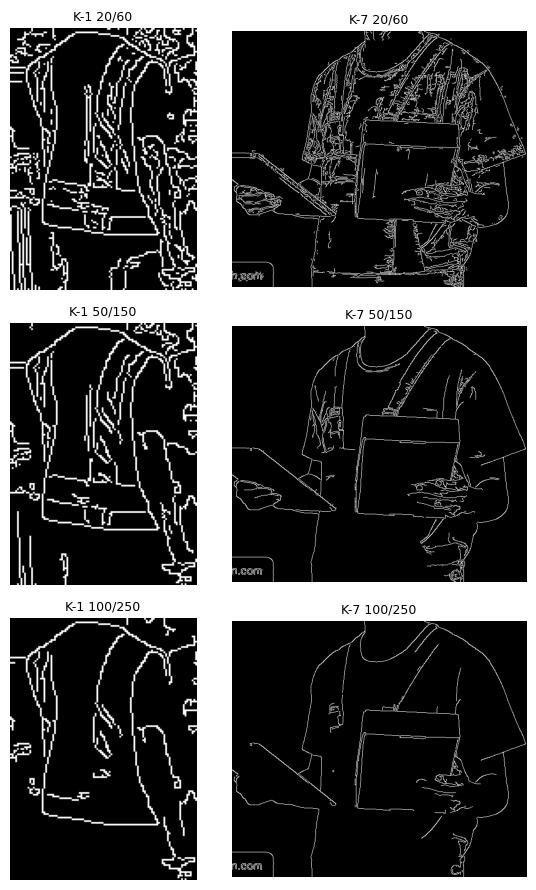

In [18]:
import experiments
d4 = experiments.d4(CTRL_IDS, gt, P, kisi='C', show_ids=['K-1', 'K-7'])   # bir yelekli, bir yeleksiz
d4.groupby(['canny', 'yelek'])[['canny_orani', 'gy_gx']].agg(['mean', 'median']).round(3)